## Model training & evaluation

In [1]:
import pandas as pd
file_path ='/Users/tuedungtruong/Documents/PythonProjects/msc-thesis/data/processed/divemt_model_input.tsv'
model_df_processed = pd.read_csv(file_path, sep ='\t')

## 1. Define document-grouped cross-validation splits 

Use GroupKFold to create 10 reusable train/test splits per language

In [2]:
import sklearn as sk
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from scipy.stats import spearmanr

In [3]:
language_splits = {}

for lang in model_df_processed['lang_id'].unique():
    lang_df = model_df_processed.loc[model_df_processed['lang_id']==lang].copy()
    doc_id = lang_df['doc_id']
    gkf = GroupKFold (n_splits=10)
    splits = list(gkf.split(lang_df, groups = doc_id))
    language_splits[lang] = splits

## 2. Define reusable cross-validation modelling function

Create a function called run_cv_model() that takes in lang_df, splits, feature_cols as parameters.

This function trains linear regression, generate held-out predictions and calculate evaluation metrics for each fold 

In [4]:
def run_cv_model(lang_df, splits, feature_cols):
    
    fold_results = []
    prediction_results =[]

    X = lang_df[feature_cols]
    y = lang_df['edit_time']

    for fold, (train_idx, test_idx) in enumerate(splits, start=1):
        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        model = LinearRegression()
        model.fit(X_train,y_train)

        y_pred=model.predict(X_test)

        mae = mean_absolute_error(y_test, y_pred)
        rho, p_value = spearmanr(y_test, y_pred)

        fold_results.append({
            "fold": fold,
            "mae": mae,
            "spearman_rho": rho,
            "spearman_p": p_value
            })
        # Raw prediction for every test observation
        test_rows = lang_df.iloc[test_idx]

        for unit_id, doc_id, actual, predicted in zip(
            test_rows["unit_id"],
            test_rows["doc_id"],
            y_test,
            y_pred
        ):
            prediction_results.append({
                "unit_id": unit_id,
                "doc_id": doc_id,
                "fold": fold,
                "actual_edit_time": actual,
                "predicted_edit_time": predicted
            })

    return (
        pd.DataFrame(fold_results),
        pd.DataFrame(prediction_results)
    )
        

### Define model specifications

In [5]:
#Define features for each prediction model
feature_sets = {
    "baseline": [
        "mt_len_wrd",
        "mt_system"
    ],
    "cometkiwi": [
        "mt_len_wrd",
        "mt_system",
        "qe_cometkiwi"
    ],
    "gemba_gemma": [
        "mt_len_wrd",
        "mt_system",
        "qe_gemba_gemma3"
    ],
    "gemba_gpt": [
        "mt_len_wrd",
        "mt_system",
        "qe_gemba_gpt4_1_mini"
    ]
}

## 3. Evaluate incremental QE  

Languages: Arabic (ara), Italian (ita), Dutch (nld), Turkish (tur), Ukrainian (ukr), Vietnamese (vie)

Model class: Multiple linear regression

Dependent variable: edit_time 

Models & their features:
1. Baseline: MT length, MT system 
2. Extended model with Pretrained QE: COMETKiwi QE score, MT length, MT system
3. Extended model with LLM-based QE (1): QE score generated by Open-weight model (Gemma 3 27B) using GEMBA-MQM framework, MT length, MT system
4. Extended model with LLM-based QE (2): QE score generated by Proprietary model (OpenAI ChatGPT-4.1-mini) using GEMBA-MQM framework, MT length, MT system


In [6]:
all_results = []
all_predictions =[]
for lang in model_df_processed['lang_id'].unique():
    lang_df = model_df_processed.loc[model_df_processed['lang_id']==lang].copy()
    fold = language_splits [lang]

    for model, features in feature_sets.items():
        fold_result, predictions = run_cv_model (lang_df = lang_df, splits = fold, feature_cols = features)

        fold_result['lang_id'] =lang
        fold_result['model'] = model

        predictions["lang_id"] = lang
        predictions["model"] = model

        all_results.append(fold_result)
        all_predictions.append(predictions)


results_df = pd.concat(
    all_results,
    ignore_index=True
)

predictions_df = pd.concat(
    all_predictions,
    ignore_index=True
)


## Models Evaluation

### 4. Summarise and save cross-validation results

In [7]:
"""
results_df.to_csv(
    "../results/linear_regression_cv_fold_results.tsv",
    sep="\t",
    index=False
)

predictions_df.to_csv(
    "../results/linear_regression_cv_predictions.tsv",
    sep="\t",
    index=False
)

"""


print(results_df.shape)
print(results_df.head(10))

(240, 6)
   fold        mae  spearman_rho    spearman_p lang_id     model
0     1  42.579809      0.394785  1.410707e-04     tur  baseline
1     2  36.464302      0.366984  4.365540e-04     tur  baseline
2     3  26.917462      0.617867  1.427666e-10     tur  baseline
3     4  46.569510      0.396029  1.337955e-04     tur  baseline
4     5  34.712020      0.458154  7.172640e-06     tur  baseline
5     6  51.284120      0.509935  3.881135e-07     tur  baseline
6     7  36.809080      0.470533  8.166044e-06     tur  baseline
7     8  33.808672      0.453706  1.861568e-05     tur  baseline
8     9  55.971701      0.450960  2.120883e-05     tur  baseline
9    10  37.329330      0.533916  1.197621e-07     tur  baseline


In [8]:
# Create summary table across the 10 folds
summary_df = (
    results_df
    .groupby(["lang_id", "model"])
    .agg(
        mean_spearman=("spearman_rho", "mean"),
        std_spearman=("spearman_rho", "std"),
        mean_mae=("mae", "mean"),
        std_mae=("mae", "std")
    )
    .reset_index()
)

print(summary_df.shape)
summary_df

#summary_df.to_csv("../results/linear_regression_summary.tsv", sep="\t",index=False)

(24, 6)


,lang_id,model,mean_spearman,std_spearman,mean_mae,std_mae
0,ara,baseline,0.468584,0.140927,80.833186,14.730322
1,ara,cometkiwi,0.542956,0.101222,78.041535,13.594557
2,ara,gemba_gemma,0.476702,0.099471,79.704927,13.860330
3,ara,gemba_gpt,0.512490,0.103990,78.921849,13.612751
4,ita,baseline,0.397253,0.072532,56.444111,7.081851
5,ita,cometkiwi,0.487178,0.083953,53.602100,6.230583
6,ita,gemba_gemma,0.447453,0.080642,55.484336,5.833441
7,ita,gemba_gpt,0.475166,0.102616,54.149555,5.982870
8,nld,baseline,0.379295,0.077502,42.006722,9.852693
9,nld,cometkiwi,0.416033,0.084805,41.402634,9.769927


### 5. Compare QE predictor models against the baseline



In [9]:
results_df.head(10)

,fold,mae,spearman_rho,spearman_p,lang_id,model
0,1,42.579809,0.394785,1.410707e-04,tur,baseline
1,2,36.464302,0.366984,4.365540e-04,tur,baseline
2,3,26.917462,0.617867,1.427666e-10,tur,baseline
3,4,46.569510,0.396029,1.337955e-04,tur,baseline
4,5,34.712020,0.458154,7.172640e-06,tur,baseline
5,6,51.284120,0.509935,3.881135e-07,tur,baseline
6,7,36.809080,0.470533,8.166044e-06,tur,baseline
7,8,33.808672,0.453706,1.861568e-05,tur,baseline
8,9,55.971701,0.450960,2.120883e-05,tur,baseline
9,10,37.329330,0.533916,1.197621e-07,tur,baseline


In [10]:
#Create df with only baseline result
baseline_df = (results_df.loc[results_df['model']=='baseline',['fold','lang_id','spearman_rho','mae']].rename(columns = {"spearman_rho":"baseline_rho","mae":"baseline_mae"}))
baseline_df.head()

,fold,lang_id,baseline_rho,baseline_mae
0,1,tur,0.394785,42.579809
1,2,tur,0.366984,36.464302
2,3,tur,0.617867,26.917462
3,4,tur,0.396029,46.569510
4,5,tur,0.458154,34.712020


In [11]:
#Create df with only QE results
qe_results_df = results_df.loc[results_df['model'] != 'baseline',['fold','model','lang_id','spearman_rho','spearman_p','mae']].rename(columns={'spearman_rho':'qe_rho','spearman_p':'qe_rho_p','mae':'qe_mae'}).copy()
qe_results_df.head()

,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae
10,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000
11,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820
12,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780
13,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553
14,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930


In [12]:
#Match QE results to baseline result from the same language and same fold
delta_df = qe_results_df.merge(baseline_df, on =['lang_id','fold'], how ='left', validate = 'many_to_one')
delta_df.head()

,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae,baseline_rho,baseline_mae
0,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000,0.394785,42.579809
1,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820,0.366984,36.464302
2,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780,0.617867,26.917462
3,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553,0.396029,46.569510
4,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930,0.458154,34.712020


In [13]:
#Calculate the differences between model with QE inputs and baseline
delta_df["delta_rho"] = (
    delta_df["qe_rho"]
    - delta_df["baseline_rho"]
)

delta_df["delta_mae"] = (
    delta_df["qe_mae"]
    - delta_df["baseline_mae"]
)
delta_df.head()

#delta_df.to_csv("../results/linear_regression_fold_deltas.tsv", sep="\t", index=False)


,fold,model,lang_id,qe_rho,qe_rho_p,qe_mae,baseline_rho,baseline_mae,delta_rho,delta_mae
0,1,cometkiwi,tur,0.397644,1.248750e-04,42.649000,0.394785,42.579809,0.002859,0.069191
1,2,cometkiwi,tur,0.448593,1.168927e-05,33.385820,0.366984,36.464302,0.081609,-3.078482
2,3,cometkiwi,tur,0.658924,2.975330e-12,27.187780,0.617867,26.917462,0.041056,0.270317
3,4,cometkiwi,tur,0.402927,9.938628e-05,45.371553,0.396029,46.569510,0.006898,-1.197957
4,5,cometkiwi,tur,0.524092,1.602484e-07,34.296930,0.458154,34.712020,0.065938,-0.415090


In [14]:
delta_summary = (
    delta_df
    .groupby(['lang_id','model'])
    .agg(
        baseline_mean_rho = ('baseline_rho', 'mean'),
        qe_mean_rho = ('qe_rho','mean'),
        mean_delta_rho = ('delta_rho','mean'),
        std_delta_rho = ('delta_rho','std'),
        baseline_mean_mae = ('baseline_mae', 'mean'),
        qe_mean_mae = ('qe_mae','mean'),
        mean_delta_mae = ('delta_mae','mean'),
        std_delta_mae = ('delta_mae','std')
    )
    .reset_index()
)
delta_summary

#delta_summary.to_csv("../results/linear_regression_delta_summary.tsv",sep="\t",index=False)

,lang_id,model,baseline_mean_rho,qe_mean_rho,mean_delta_rho,std_delta_rho,baseline_mean_mae,qe_mean_mae,mean_delta_mae,std_delta_mae
0,ara,cometkiwi,0.468584,0.542956,0.074372,0.080709,80.833186,78.041535,-2.791651,2.991744
1,ara,gemba_gemma,0.468584,0.476702,0.008118,0.079575,80.833186,79.704927,-1.128258,2.803599
2,ara,gemba_gpt,0.468584,0.512490,0.043906,0.053693,80.833186,78.921849,-1.911336,1.830628
3,ita,cometkiwi,0.397253,0.487178,0.089925,0.061053,56.444111,53.602100,-2.842011,2.248416
4,ita,gemba_gemma,0.397253,0.447453,0.050200,0.031688,56.444111,55.484336,-0.959775,1.837898
5,ita,gemba_gpt,0.397253,0.475166,0.077913,0.070974,56.444111,54.149555,-2.294556,2.682966
6,nld,cometkiwi,0.379295,0.416033,0.036737,0.026875,42.006722,41.402634,-0.604088,0.729959
7,nld,gemba_gemma,0.379295,0.400570,0.021275,0.011401,42.006722,41.800635,-0.206087,0.400128
8,nld,gemba_gpt,0.379295,0.421055,0.041760,0.030750,42.006722,41.323663,-0.683058,0.903901
9,tur,cometkiwi,0.465287,0.496860,0.031574,0.035149,40.244601,39.311082,-0.933518,1.064486


## 6. Inspect QE score distributions

In [15]:
qe_columns = [
    "qe_cometkiwi",
    "qe_gemba_gemma3",
    "qe_gemba_gpt4_1_mini"
]

model_df_processed[qe_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
qe_cometkiwi,5147.0,0.833735,0.069857,0.209202,0.812376,0.858506,0.880869,0.910036
qe_gemba_gemma3,5147.0,-5.325432,7.809825,-25.000000,-6.000000,-1.000000,-1.000000,0.000000
qe_gemba_gpt4_1_mini,5147.0,-8.877987,10.005841,-25.000000,-25.000000,-6.000000,-1.000000,0.000000


In [16]:
gemba_columns = [
    "qe_gemba_gemma3",
    "qe_gemba_gpt4_1_mini"
]

for col in gemba_columns:

    print("\n", col)

    print("Unique scores:",
          model_df_processed[col].nunique())

    print("% score = 0:",
          (model_df_processed[col] == 0).mean() * 100)

    print("% score = -25:",
          (model_df_processed[col] == -25).mean() * 100)


 qe_gemba_gemma3
Unique scores: 14
% score = 0: 22.809403536040413
% score = -25: 12.201282300369147

 qe_gemba_gpt4_1_mini
Unique scores: 16
% score = 0: 24.84942685059258
% score = -25: 26.07344083932388


In [17]:
delta_df.groupby(
    ["lang_id", "model"]
)["delta_rho"].agg(
    ["mean", "std", "min", "max"]
)

mean       std       min       max
lang_id model                                              
ara     cometkiwi    0.074372  0.080709 -0.048470  0.240256
        gemba_gemma  0.008118  0.079575 -0.125043  0.093236
        gemba_gpt    0.043906  0.053693 -0.038308  0.122105
ita     cometkiwi    0.089925  0.061053 -0.022811  0.167200
        gemba_gemma  0.050200  0.031688  0.009266  0.089281
        gemba_gpt    0.077913  0.070974 -0.032827  0.168596
nld     cometkiwi    0.036737  0.026875  0.002700  0.078715
        gemba_gemma  0.021275  0.011401  0.001704  0.040763
        gemba_gpt    0.041760  0.030750  0.001644  0.091789
tur     cometkiwi    0.031574  0.035149 -0.009447  0.086090
        gemba_gemma  0.010490  0.023777 -0.018819  0.042324
        gemba_gpt    0.025040  0.025784 -0.011359  0.066084
ukr     cometkiwi    0.026549  0.019030  0.000760  0.062179
        gemba_gemma  0.016002  0.020372 -0.026335  0.052412
        gemba_gpt    0.022587  0.012042 -0.004973  0.037192
vie     cometkiwi    0.086615  0.047233  0.016189  0.180126
        gemba_gemma  0.034879  0.032699 -0.039102  0.073618
        gemba_gpt    0.044191  0.041912 -0.020122  0.108274

In [18]:

consistency_df = (
    delta_df
    .groupby(["lang_id", "model"])
    .agg(
        n_folds=("delta_rho", "size"),

        positive_rho_folds=(
            "delta_rho",
            lambda x: (x > 0).sum()
        ),

        negative_rho_folds=(
            "delta_rho",
            lambda x: (x < 0).sum()
        ),

        median_delta_rho=(
            "delta_rho",
            "median"
        )
    )
    .reset_index()
)

consistency_df["pct_positive_rho"] = (
    consistency_df["positive_rho_folds"]
    / consistency_df["n_folds"]
    * 100
)

consistency_df

,lang_id,model,n_folds,positive_rho_folds,negative_rho_folds,median_delta_rho,pct_positive_rho
0,ara,cometkiwi,10,8,2,0.076692,80.0
1,ara,gemba_gemma,10,7,3,0.021741,70.0
2,ara,gemba_gpt,10,8,2,0.042904,80.0
3,ita,cometkiwi,10,9,1,0.107469,90.0
4,ita,gemba_gemma,10,10,0,0.051814,100.0
5,ita,gemba_gpt,10,8,2,0.097151,80.0
6,nld,cometkiwi,10,10,0,0.036008,100.0
7,nld,gemba_gemma,10,10,0,0.020433,100.0
8,nld,gemba_gpt,10,10,0,0.038200,100.0
9,tur,cometkiwi,10,9,1,0.017894,90.0


In [19]:
#No. of improved folds + meandian delta
mae_consistency_df = (
    delta_df
    .groupby(["lang_id", "model"])
    .agg(
        improved_mae_folds=(
            "delta_mae",
            lambda x: (x < 0).sum()
        ),

        worse_mae_folds=(
            "delta_mae",
            lambda x: (x > 0).sum()
        ),

        median_delta_mae=(
            "delta_mae",
            "median"
        )
    )
    .reset_index()
)

mae_consistency_df

,lang_id,model,improved_mae_folds,worse_mae_folds,median_delta_mae
0,ara,cometkiwi,8,2,-2.286152
1,ara,gemba_gemma,5,5,-0.568997
2,ara,gemba_gpt,8,2,-2.148966
3,ita,cometkiwi,9,1,-3.131219
4,ita,gemba_gemma,8,2,-1.384859
5,ita,gemba_gpt,8,2,-2.921072
6,nld,cometkiwi,9,1,-0.681708
7,nld,gemba_gemma,8,2,-0.197366
8,nld,gemba_gpt,8,2,-0.682175
9,tur,cometkiwi,8,2,-0.806523


In [20]:
"""
consistency_df.to_csv(
    "../results/spearman_fold_consistency.tsv",
    sep="\t",
    index=False
)

mae_consistency_df.to_csv(
    "../results/mae_fold_consistency.tsv",
    sep="\t",
    index=False
)

"""


'\nconsistency_df.to_csv(\n    "../results/spearman_fold_consistency.tsv",\n    sep="\t",\n    index=False\n)\n\nmae_consistency_df.to_csv(\n    "../results/mae_fold_consistency.tsv",\n    sep="\t",\n    index=False\n)\n\n'

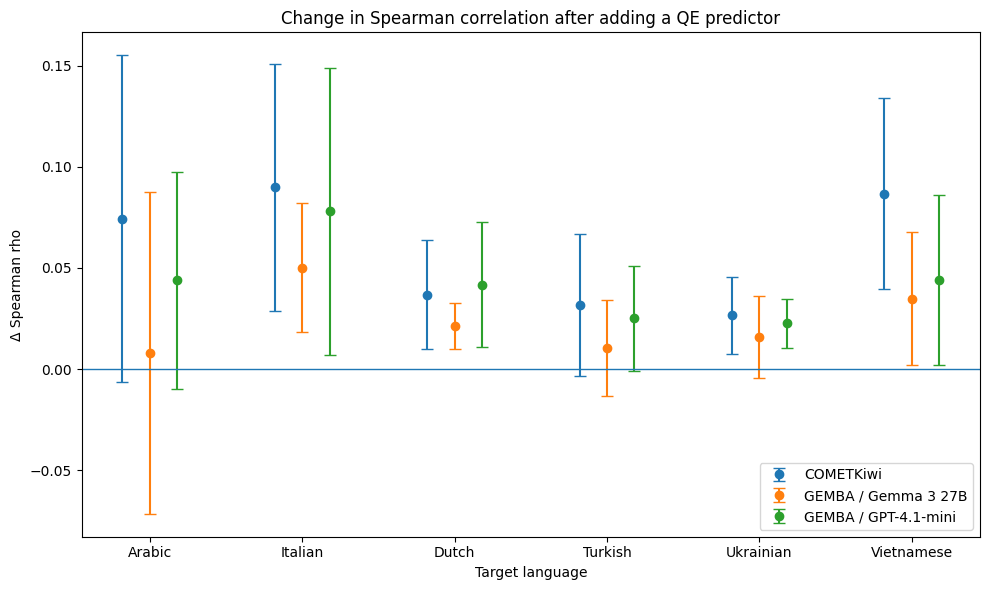

In [21]:
import matplotlib.pyplot as plt
import numpy as np

languages = ["ara", "ita", "nld", "tur", "ukr", "vie"]

models = [
    "cometkiwi",
    "gemba_gemma",
    "gemba_gpt"
]

labels = {
    "cometkiwi": "COMETKiwi",
    "gemba_gemma": "GEMBA / Gemma 3 27B",
    "gemba_gpt": "GEMBA / GPT-4.1-mini"
}

x = np.arange(len(languages))
offsets = [-0.18, 0, 0.18]

fig, ax = plt.subplots(figsize=(10, 6))

for offset, model in zip(offsets, models):

    plot_df = (
        delta_summary[
            delta_summary["model"] == model
        ]
        .set_index("lang_id")
        .loc[languages]
    )

    ax.errorbar(
        x + offset,
        plot_df["mean_delta_rho"],
        yerr=plot_df["std_delta_rho"],
        fmt="o",
        capsize=4,
        label=labels[model]
    )

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Arabic", "Italian", "Dutch",
     "Turkish", "Ukrainian", "Vietnamese"]
)

ax.set_xlabel("Target language")
ax.set_ylabel("Δ Spearman rho")
ax.set_title(
    "Change in Spearman correlation after adding a QE predictor"
)

ax.legend()
plt.tight_layout()
plt.show()

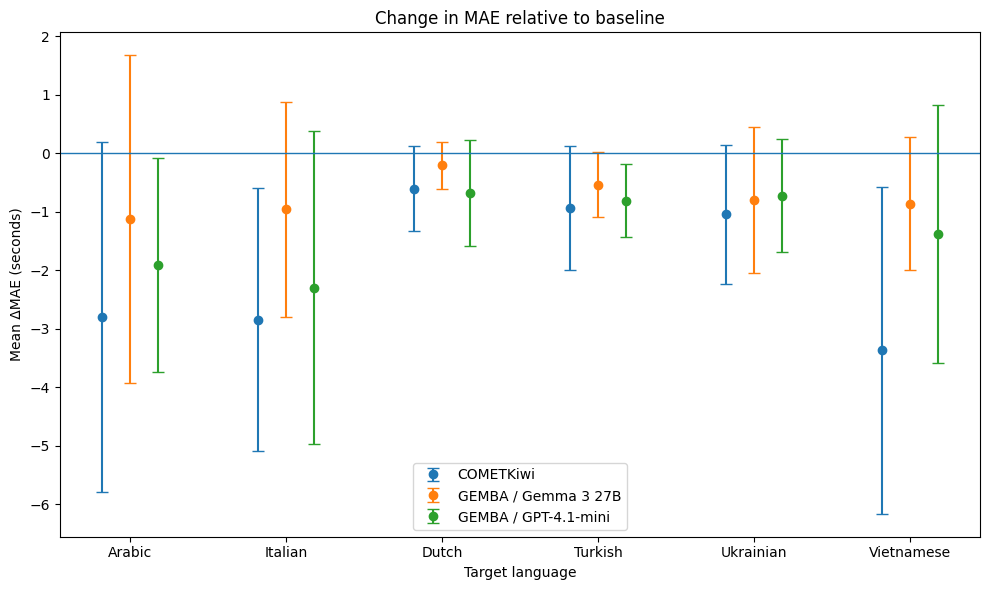

In [22]:
# change in MAE relative to baseline
fig, ax = plt.subplots(figsize=(10, 6))

for offset, model in zip(offsets, models):

    plot_df = (
        delta_summary[
            delta_summary["model"] == model
        ]
        .set_index("lang_id")
        .loc[languages]
    )

    ax.errorbar(
        x + offset,
        plot_df["mean_delta_mae"],
        yerr=plot_df["std_delta_mae"],
        fmt="o",
        capsize=4,
        label=labels[model]
    )

ax.axhline(0, linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Arabic", "Italian", "Dutch",
     "Turkish", "Ukrainian", "Vietnamese"]
)

ax.set_xlabel("Target language")
ax.set_ylabel("Mean ΔMAE (seconds)")
ax.set_title("Change in MAE relative to baseline")

ax.legend()
plt.tight_layout()
plt.show()

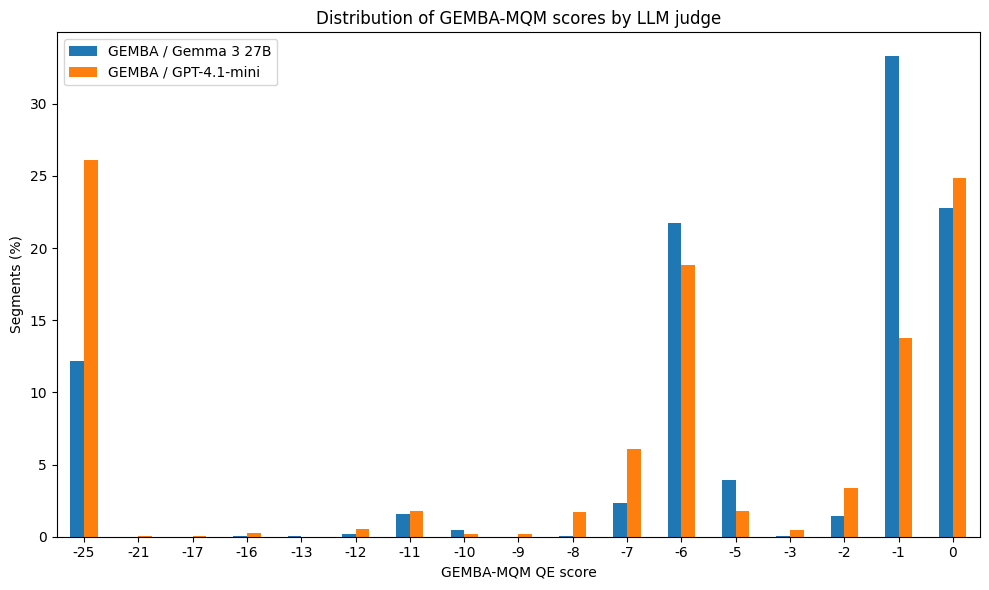

In [23]:
gemba_score_distribution = pd.concat(
    {
        "GEMBA / Gemma 3 27B":
            model_df_processed["qe_gemba_gemma3"]
            .value_counts(normalize=True)
            .mul(100),

        "GEMBA / GPT-4.1-mini":
            model_df_processed["qe_gemba_gpt4_1_mini"]
            .value_counts(normalize=True)
            .mul(100)
    },
    axis=1
).fillna(0).sort_index()

gemba_score_distribution
ax = gemba_score_distribution.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_xlabel("GEMBA-MQM QE score")
ax.set_ylabel("Segments (%)")
ax.set_title("Distribution of GEMBA-MQM scores by LLM judge")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
